# Load the trained model


In [4]:
%run train.ipynb

18 features: ['homeplanet', 'cryosleep', 'destination', 'vip', 'deck', 'side', 'age', 'group_size', 'solo', 'cabin_num', 'total_spend', 'no_spend', 'log_roomservice', 'log_foodcourt', 'log_shoppingmall', 'log_spa', 'log_vrdeck', 'log_total_spend']
(5215, 18) (1739, 18) (1739, 18)
(5215,) (1739,) (1739,)
fold 0: acc=0.8181  trees=1177
fold 1: acc=0.8095  trees=1097
fold 2: acc=0.8246  trees=1127
fold 3: acc=0.8124  trees=1397
fold 4: acc=0.8129  trees=874
CV accuracy = 0.8155 ± 0.0053  | trees for final model: 1127
0:	learn: 0.7626079	test: 0.7492812	best: 0.7492812 (0)	total: 4.17ms	remaining: 12.5s
200:	learn: 0.8222435	test: 0.7958597	best: 0.8010351 (154)	total: 726ms	remaining: 10.1s
400:	learn: 0.8433365	test: 0.8004600	best: 0.8021852 (338)	total: 1.46s	remaining: 9.48s
600:	learn: 0.8661553	test: 0.8027602	best: 0.8067855 (550)	total: 2.24s	remaining: 8.93s
800:	learn: 0.8832215	test: 0.8056354	best: 0.8073606 (719)	total: 3s	remaining: 8.25s
Stopped by overfitting detector  (20

## Metric functions
The positive class is the larger label in `model.classes_`, which means the passenger was transported.

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


def get_confusion_matrix(X, y):
    predictions = model.predict(X).astype(int).ravel()
    return confusion_matrix(y, predictions, labels=model.classes_)


def calculate_metrics(matrix):
    tn, fp, fn, tp = matrix.ravel()

    accuracy = (tp + tn) / matrix.sum()
    precision = tp / (tp + fp)
    recall = tp / (tp + fn)

    return {
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "accuracy": accuracy,
        "error_rate": 1 - accuracy,
        "precision": precision,
        "recall": recall,
        "sensitivity": recall,  # sensitivity and recall are the same formula
        "specificity": tn / (tn + fp),
        "f1": 2 * precision * recall / (precision + recall),
    }


def plot_confusion_matrix(matrix, set_name, class_names):
    display = ConfusionMatrixDisplay(matrix, display_labels=class_names)
    display.plot(cmap="Blues", colorbar=False)
    plt.title(f"Confusion matrix: {set_name} set")
    plt.show()

# Evaluate every data set

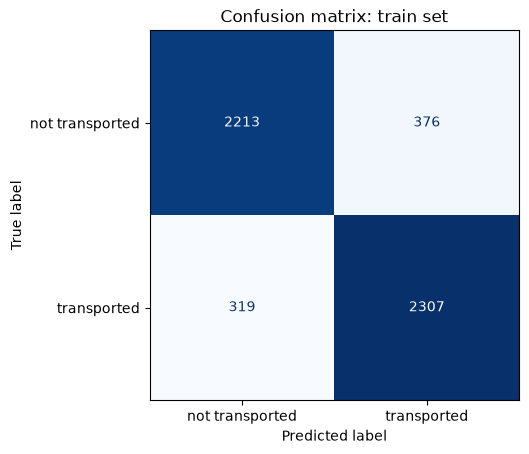

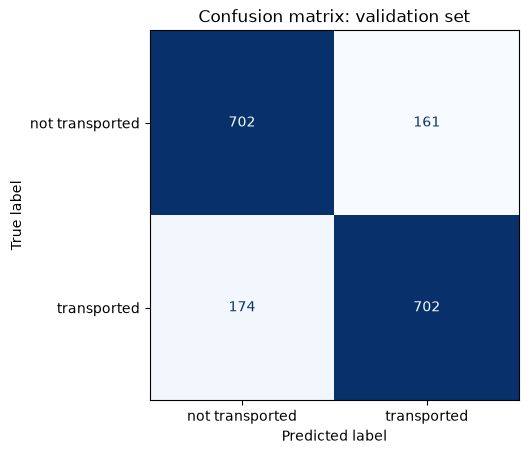

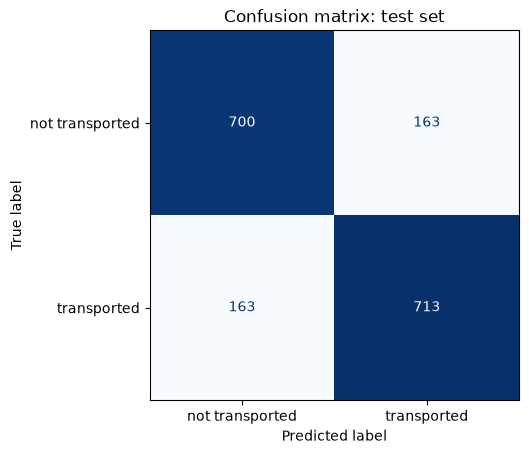

,TN,FP,FN,TP,accuracy,error_rate,precision,recall,sensitivity,specificity,f1
train,2213.0,376.0,319.0,2307.0,0.8667,0.1333,0.8599,0.8785,0.8785,0.8548,0.8691
validation,702.0,161.0,174.0,702.0,0.8074,0.1926,0.8134,0.8014,0.8014,0.8134,0.8074
test,700.0,163.0,163.0,713.0,0.8125,0.1875,0.8139,0.8139,0.8139,0.8111,0.8139


In [6]:
data_sets = {
    "train": (X_train_cb, y_train),
    "validation": (X_val_cb, y_val),
    "test": (X_test_cb, y_test),
}
class_names = [f"not {target}", target]

results = {}
for set_name, (X, y) in data_sets.items():
    matrix = get_confusion_matrix(X, y)
    plot_confusion_matrix(matrix, set_name, class_names)
    results[set_name] = calculate_metrics(matrix)

pd.DataFrame(results).T.round(4)

# ROC curve and AUC

The ROC curve shows the trade-off at every decision threshold, using `predict_proba` instead of the 0/1 predictions:

- **True positive rate (y-axis):** share of transported passengers the model finds. This is the same as recall.
- **False positive rate (x-axis):** share of non-transported passengers wrongly flagged. This equals 1 - specificity.

**AUC** is the area under that curve. It is the chance that a random transported passenger gets a higher score than a random non-transported passenger: 0.5 is random guessing and 1.0 is perfect.

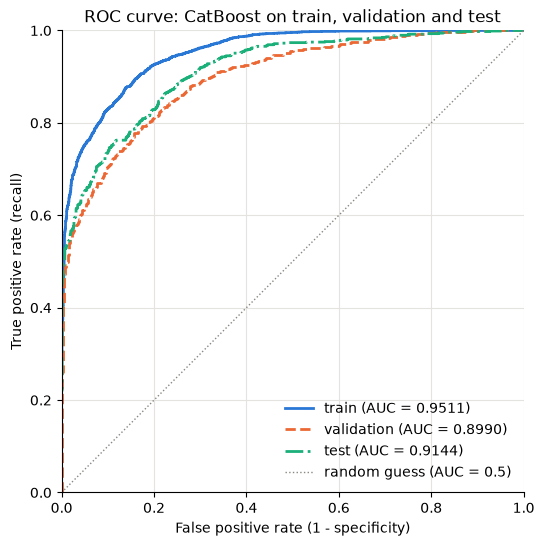

,auc
train,0.9511
validation,0.8990
test,0.9144


In [12]:
from sklearn.metrics import roc_curve, roc_auc_score

# Same data sets as the evaluation above; each one keeps its own color and line style
roc_styles = {
    "train": {"color": "#2a78d6", "linestyle": "-"},
    "validation": {"color": "#eb6834", "linestyle": "--"},
    "test": {"color": "#1baf7a", "linestyle": "-."},
}

fig, ax = plt.subplots(figsize=(6, 6))
auc_scores = {}

for set_name, (X, y) in data_sets.items():
    # Column 1 of predict_proba is the positive class (transported)
    scores = model.predict_proba(X)[:, 1]
    fpr, tpr, _ = roc_curve(y, scores)
    auc_scores[set_name] = roc_auc_score(y, scores)
    ax.plot(fpr, tpr, linewidth=2, label=f"{set_name} (AUC = {auc_scores[set_name]:.4f})",
            **roc_styles[set_name])

ax.plot([0, 1], [0, 1], color="#898781", linewidth=1, linestyle=":", label="random guess (AUC = 0.5)")
ax.set_title("ROC curve: CatBoost on train, validation and test")
ax.set_xlabel("False positive rate (1 - specificity)")
ax.set_ylabel("True positive rate (recall)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect("equal")
ax.grid(color="#e4e3df", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="lower right", frameon=False)
plt.show()

pd.Series(auc_scores, name="auc").round(4).to_frame()